# Intelligent Predictive Maintenance & Machine Failure Risk Management

## Project Overview

The objective of this project is to develop a machine learning-based
predictive maintenance system that identifies the possibility of
industrial machine failures using operational sensor measurements.

The project uses the AI4I 2020 Predictive Maintenance Dataset.

## Business Objectives and Success Criteria

### Operational Objectives

The manufacturing organization aims to improve machine reliability by identifying potential failures before they cause unexpected production interruptions.

The proposed predictive maintenance solution aims to:

1. Detect machines with a high probability of failure.
2. Reduce unexpected machine downtime.
3. Minimize unnecessary maintenance inspections.
4. Support maintenance teams in prioritizing machines based on failure risk.
5. Improve operational efficiency through data-driven maintenance decisions.

### Prediction Target

The target variable is `Machine failure`.

- 0: Normal machine operation.
- 1: Machine failure.

This is a binary classification problem.

### Success Criteria

The project will be evaluated based on:

- High recall for the machine failure class.
- Good precision to avoid excessive unnecessary inspections.
- Strong F1-score to balance precision and recall.
- Suitable PR-AUC for evaluating minority-class detection.
- Lower hypothetical maintenance cost based on false positives and false negatives.
- Consistent performance on unseen test data.

The final model should balance failure detection and inspection costs rather than maximizing accuracy alone.

### Consequences of Missed Failures

A false negative occurs when the model predicts normal operation even though the machine actually experiences failure.

Possible consequences include:

- Unexpected machine breakdown.
- Production downtime.
- Increased repair and maintenance expenses.
- Delayed product deliveries.
- Reduced manufacturing productivity.

Therefore, identifying actual failures is a major operational priority.

The final decision threshold should be selected based on validation results and realistic maintenance cost assumptions.

# Phase 1 — Business Understanding, Data Audit and Preparation

## Install and import libraries

In [1]:
!pip install tensorflow scikit-learn pandas numpy matplotlib seaborn -q

In [2]:
import os
import zipfile
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


##  Dataset Loading

The AI4I 2020 dataset contains 10,000 records and 14 columns.

It includes:
- Product quality information.
- Air and process temperatures.
- Rotational speed.
- Torque.
- Tool wear.
- Machine failure indicators.

The dataset will be loaded and inspected before performing
data cleaning and exploratory data analysis.

In [3]:
from google.colab import files

uploaded = files.upload()

Saving ai4i+2020+predictive+maintenance+dataset.zip to ai4i+2020+predictive+maintenance+dataset (4).zip


In [4]:
zip_path = next(
    name for name in uploaded.keys()
    if name.endswith(".zip")
)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/predictive_maintenance")

df = pd.read_csv(
    "/content/predictive_maintenance/ai4i2020.csv"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


## Data Understanding

In [5]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head(5))

print("\nColumn Names:")
print(df.columns.tolist())



Dataset Shape: (10000, 14)

First 5 Records:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0



Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [6]:
print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


## Data Quality Audit

In [7]:
#checking the missing values
df.isnull().sum().sum()


np.int64(0)

In [8]:
# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())



Duplicate Records: 0


In [9]:
# Data types
print("\nData Types:")
print(df.dtypes)



Data Types:
UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object


In [10]:
# Unique values
print("\nProduct Type Categories:")
print(df["Type"].value_counts())


Product Type Categories:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


In [11]:
# Target distribution
print("\nMachine Failure Distribution:")
print(df["Machine failure"].value_counts())


Machine Failure Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [12]:
# Check invalid readings
sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for col in sensor_columns:
    print(
        col,
        "Minimum:", df[col].min(),
        "Maximum:", df[col].max()
    )

print("\nInvalid categorical values:")
print(df[~df["Type"].isin(["L", "M", "H"])])

Air temperature [K] Minimum: 295.3 Maximum: 304.5
Process temperature [K] Minimum: 305.7 Maximum: 313.8
Rotational speed [rpm] Minimum: 1168 Maximum: 2886
Torque [Nm] Minimum: 3.8 Maximum: 76.6
Tool wear [min] Minimum: 0 Maximum: 253

Invalid categorical values:
Empty DataFrame
Columns: [UDI, Product ID, Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Machine failure, TWF, HDF, PWF, OSF, RNF]
Index: []


In [13]:
# Check valid target values
print("Invalid target values:")
print(df[~df["Machine failure"].isin([0, 1])])

# Check unexpected product categories
print("\nUnexpected product categories:")
print(df[~df["Type"].isin(["L", "M", "H"])])

# Check potentially invalid sensor readings
validation_checks = {
    "Non-positive Air Temperature":
        df["Air temperature [K]"] <= 0,

    "Non-positive Process Temperature":
        df["Process temperature [K]"] <= 0,

    "Non-positive Rotational Speed":
        df["Rotational speed [rpm]"] <= 0,

    "Negative Torque":
        df["Torque [Nm]"] < 0,

    "Negative Tool Wear":
        df["Tool wear [min]"] < 0
}

for name, condition in validation_checks.items():
    print(name, ":", condition.sum())

# Investigate temperature relationship separately
print(
    "\nProcess temperature <= Air temperature:",
    (
        df["Process temperature [K]"] <=
        df["Air temperature [K]"]
    ).sum()
)


Invalid target values:
Empty DataFrame
Columns: [UDI, Product ID, Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Machine failure, TWF, HDF, PWF, OSF, RNF]
Index: []

Unexpected product categories:
Empty DataFrame
Columns: [UDI, Product ID, Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Machine failure, TWF, HDF, PWF, OSF, RNF]
Index: []
Non-positive Air Temperature : 0
Non-positive Process Temperature : 0
Non-positive Rotational Speed : 0
Negative Torque : 0
Negative Tool Wear : 0

Process temperature <= Air temperature: 0


In [14]:
# Check identifier consistency

print("Unique UDI:", df["UDI"].nunique())

print("Unique Product IDs:", df["Product ID"].nunique())

print("\nDuplicate UDI:", df["UDI"].duplicated().sum())

print("\nDuplicate Product IDs:", df["Product ID"].duplicated().sum())

print("\nProduct Type Values:")
print(sorted(df["Type"].dropna().unique()))

Unique UDI: 10000
Unique Product IDs: 10000

Duplicate UDI: 0

Duplicate Product IDs: 0

Product Type Values:
['H', 'L', 'M']


### Category and Identifier Findings

The product quality category is expected to contain L, M and H.

UDI and Product ID are identification fields rather than operational sensor measurements.

They are excluded from predictive modeling to prevent the model from learning identifier-specific patterns.

The category values and identifier uniqueness are checked before model development.

# Exploratory Data Analysis (EDA)

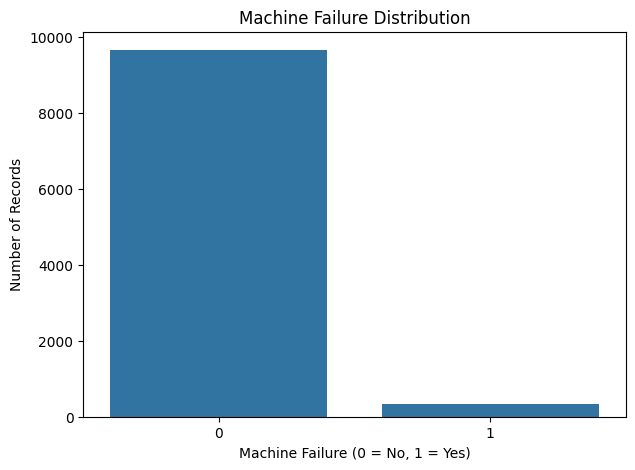

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


In [15]:
# target distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

plt.show()

failure_percentage = (
    df["Machine failure"].value_counts(normalize=True) * 100
)

print(failure_percentage)

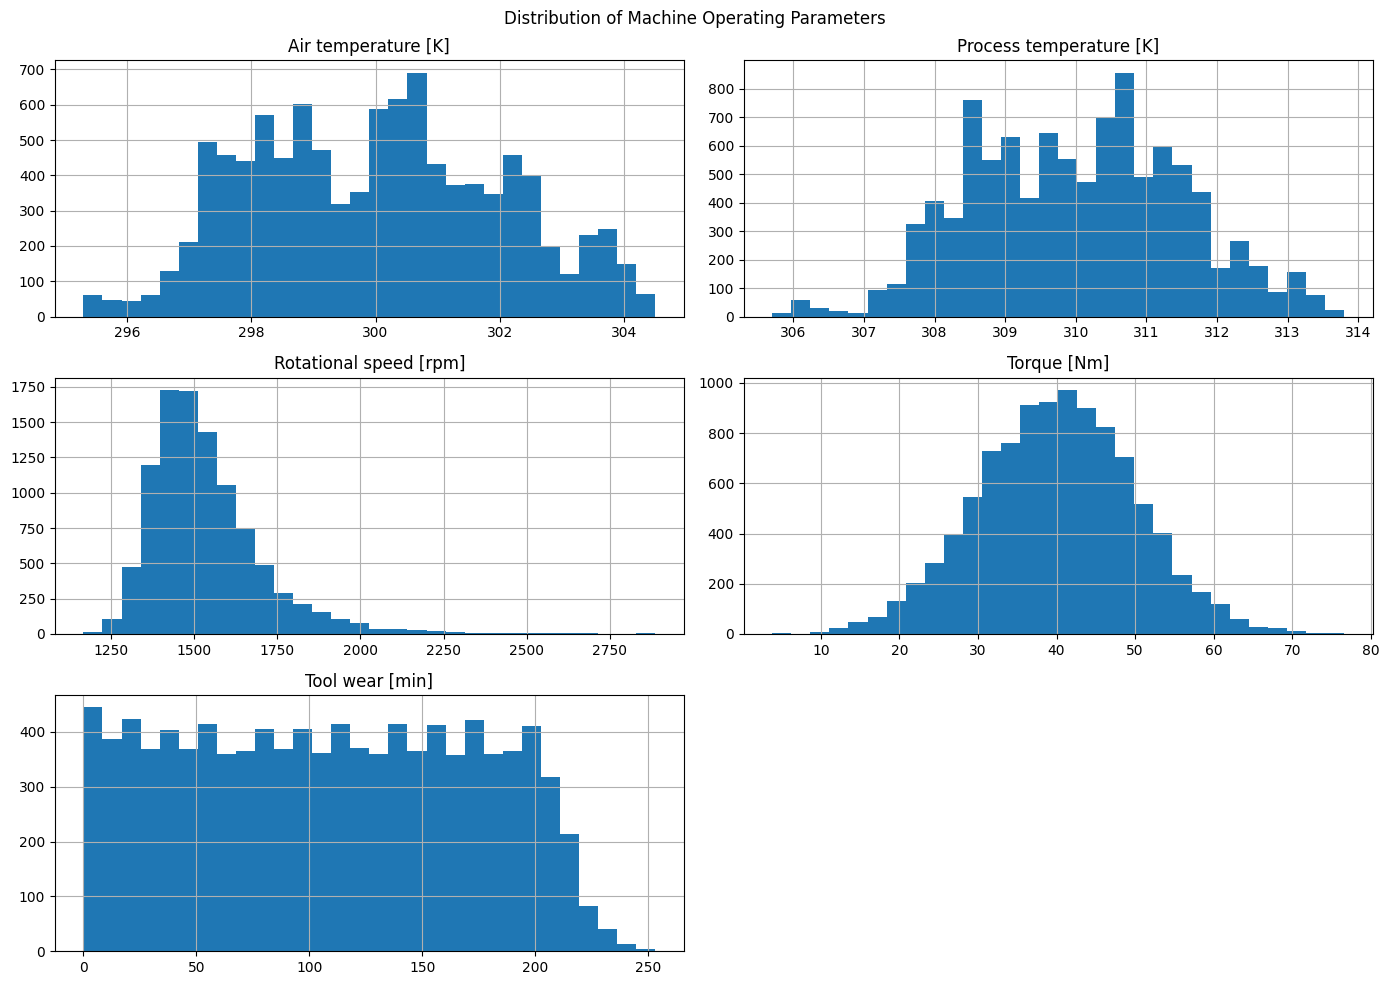

In [16]:
#Numerical feature distributions
df[sensor_columns].hist(
    figsize=(14, 10),
    bins=30
)

plt.suptitle("Distribution of Machine Operating Parameters")
plt.tight_layout()
plt.show()

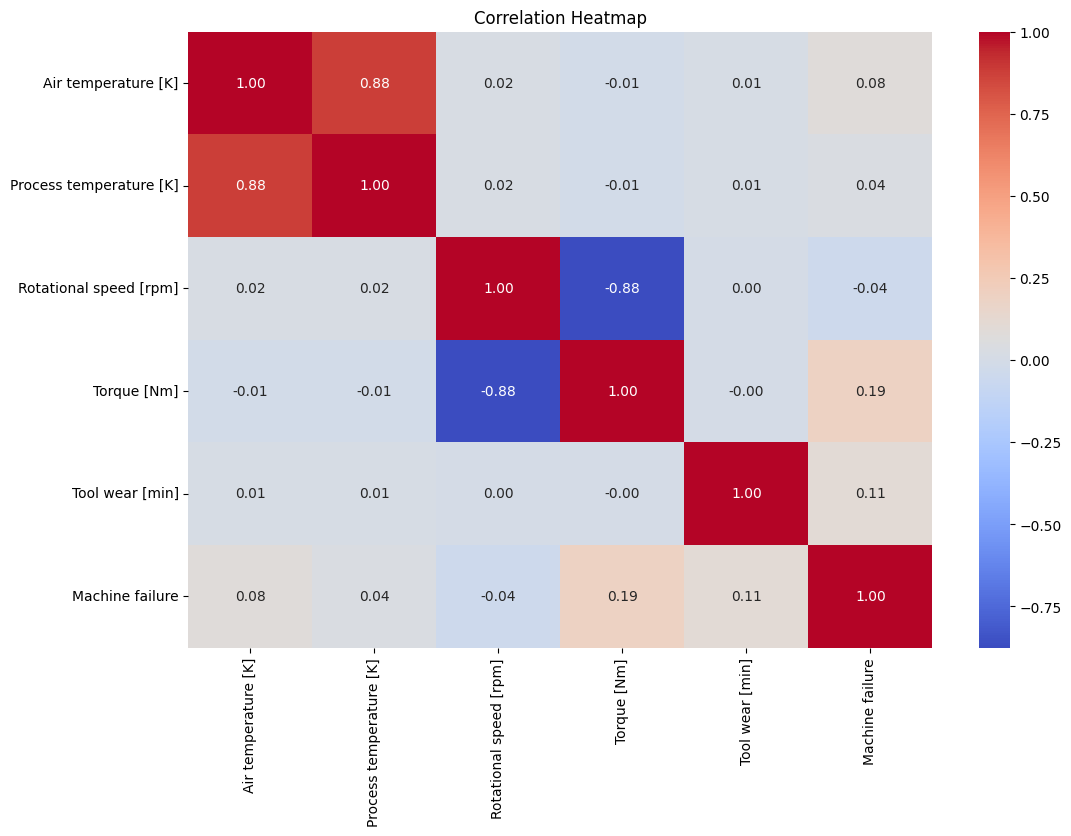

In [17]:
plt.figure(figsize=(12, 8))

correlation = df[sensor_columns + ["Machine failure"]].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

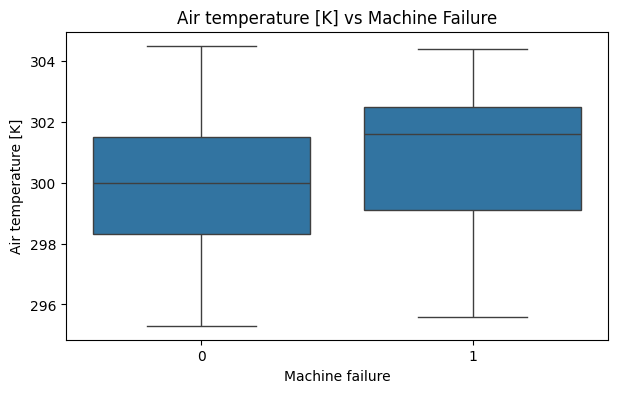

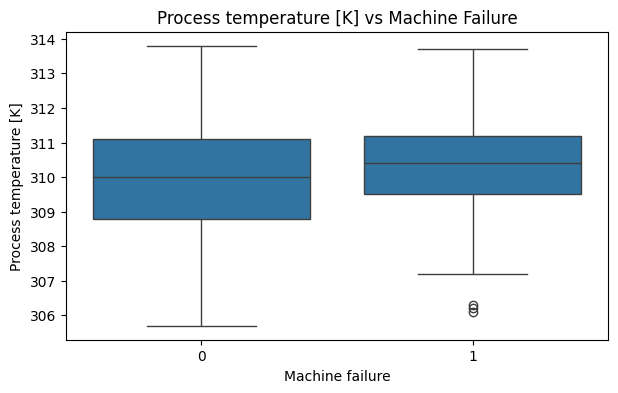

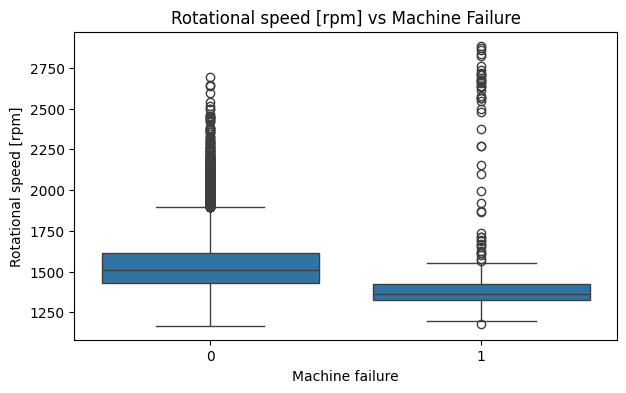

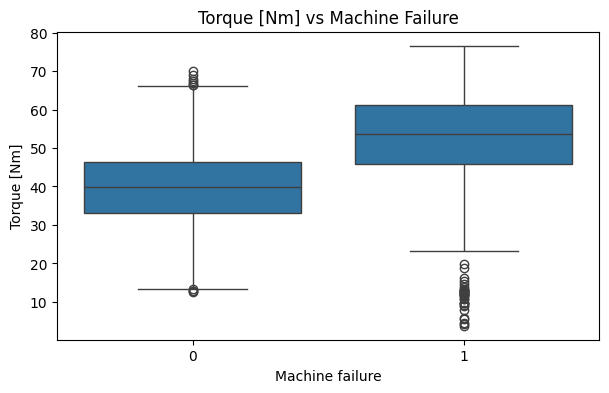

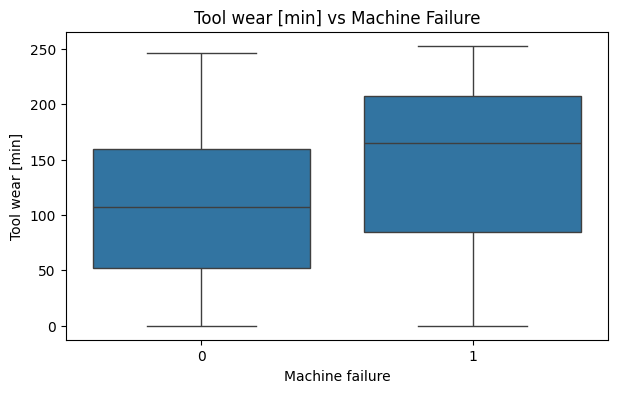

In [18]:
# Sensor values by machine failure
for col in sensor_columns:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="Machine failure",
        y=col
    )

    plt.title(f"{col} vs Machine Failure")
    plt.show()

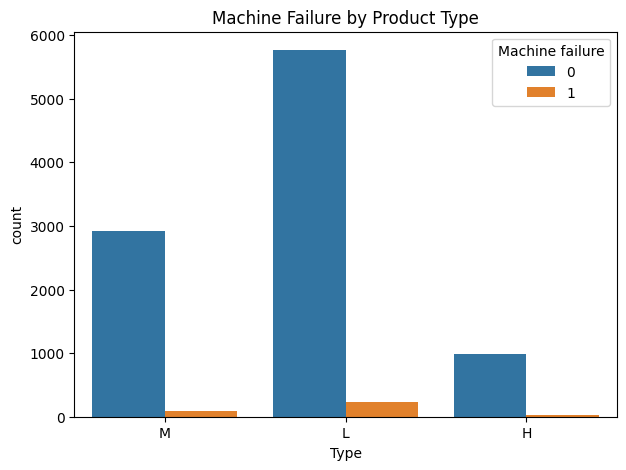

In [19]:
# Failure distribution by product type
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Type",
    hue="Machine failure"
)

plt.title("Machine Failure by Product Type")
plt.show()

In [20]:
outlier_summary = []

for col in sensor_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": len(outliers)
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df)

,Feature,Lower Bound,Upper Bound,Outlier Count
0,Air temperature [K],293.50,306.30,0
1,Process temperature [K],305.35,314.55,0
2,Rotational speed [rpm],1139.50,1895.50,418
3,Torque [Nm],12.80,67.20,69
4,Tool wear [min],-110.50,325.50,0


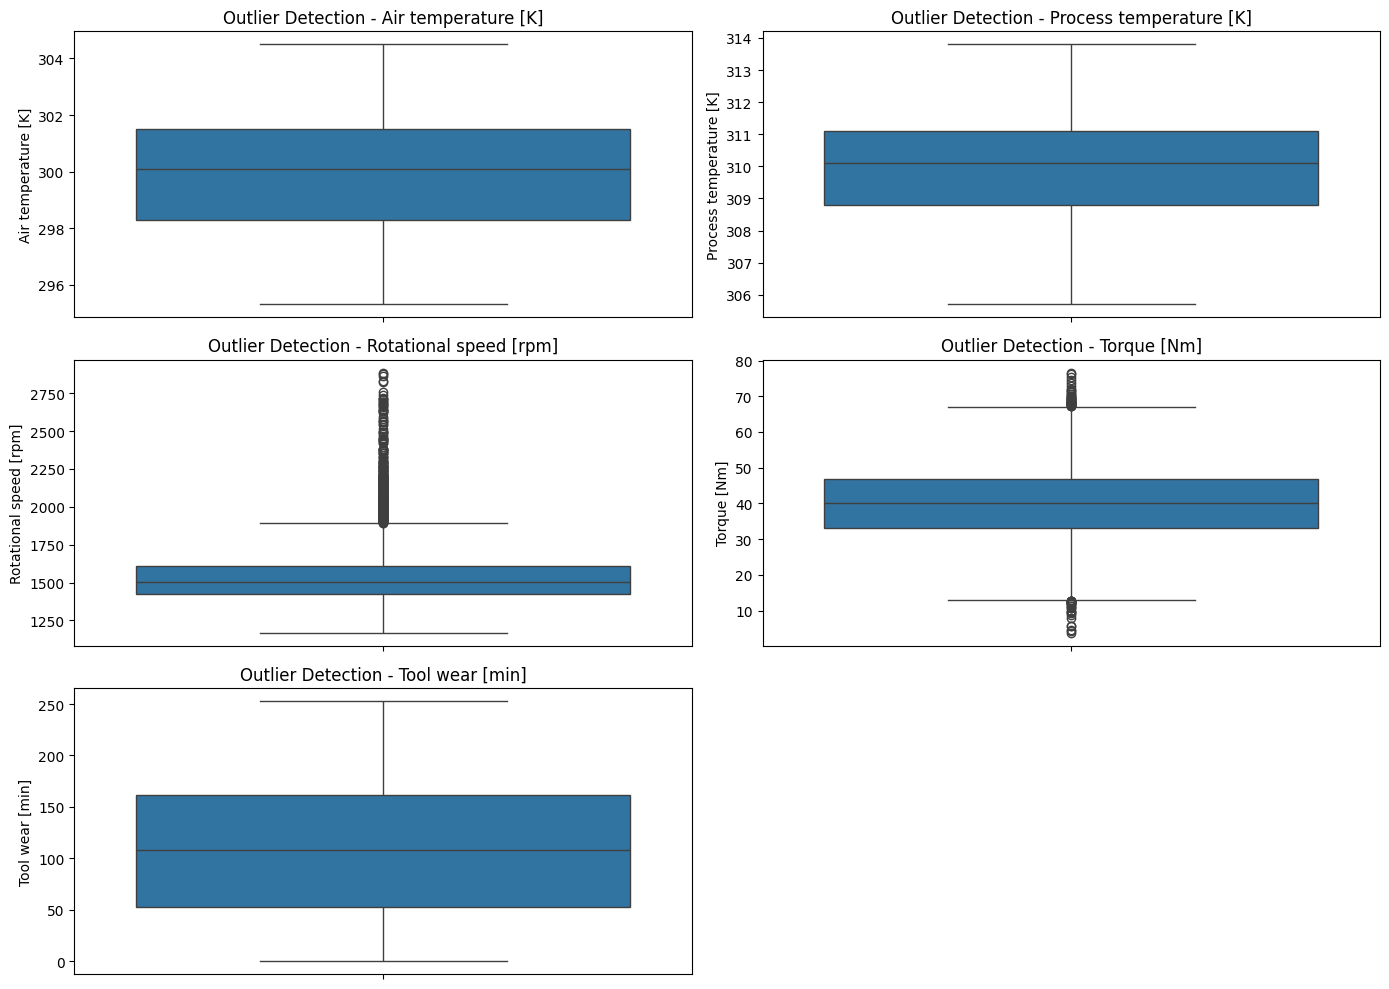

In [21]:
plt.figure(figsize=(14, 10))

for i, col in enumerate(sensor_columns, 1):

    plt.subplot(3, 2, i)

    sns.boxplot(
        y=df[col]
    )

    plt.title(f"Outlier Detection - {col}")

plt.tight_layout()
plt.show()


### EDA Observations

After exploring the dataset, I observed the following:

- The dataset is highly imbalanced, with only 3.39% of observations representing machine failures.
- Rotational speed and torque contain some potential outliers.
- The sensor measurements show different patterns across normal and failure observations.
- The correlation heatmap helps identify relationships between operating parameters and machine failure.
- Product type also provides useful information for comparing failure distributions.

These observations help understand the dataset and guide the selection of features for model development.

Correlation indicates association between variables and does not necessarily mean that one variable causes machine failure.


##  Data Cleaning and Feature Engineering



The objective of this step is to prepare a reliable dataset for machine learning by identifying data quality issues, applying justified cleaning operations and creating meaningful features from existing sensor measurements.

### Data Cleaning Strategy

The following operations are performed:

1. **Missing Values:** Identify missing values and apply suitable imputation only if required.
2. **Duplicate Records:** Identify and remove confirmed exact duplicate records.
3. **Category Validation:** Verify that the Type column contains only L, M and H.
4. **Invalid Measurements:** Investigate negative torque, negative tool wear, non-positive temperatures and rotational speed.
5. **Outlier Treatment:** Identify potential outliers using the IQR method. Retain unusual but valid measurements because they may contain important failure information.
6. **Identifier Removal:** Exclude UDI and Product ID from predictive features.
7. **Leakage Prevention:** Exclude TWF, HDF, PWF, OSF and RNF because they contain failure-mode information.

Cleaning operations are based on actual data-quality findings. Artificial missing values and unnecessary data modifications are avoided.

In [22]:
# Create a working copy
df_clean = df.copy()

# Remove exact duplicates if present
before = len(df_clean)

df_clean = df_clean.drop_duplicates()

after = len(df_clean)

print("Duplicate records removed:", before - after)

# Check missing values after duplicate removal
print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nCleaned Dataset Shape:", df_clean.shape)

Duplicate records removed: 0

Missing Values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Cleaned Dataset Shape: (10000, 14)



### Data Quality Findings

The data quality audit identified the following findings:

- No missing values were found.
- No exact duplicate records were found.
- No unexpected product categories were identified.
- No invalid target values were identified.
- No negative torque, negative tool wear or non-positive sensor readings were found.

Since the original dataset is relatively clean, no unnecessary imputation or record removal was performed.

The cleaning workflow preserves valid observations for further analysis.


### Feature Engineering

Feature engineering involves creating additional meaningful variables from existing dataset columns to improve the information available to machine learning models.

For this project, the following feature is created: **Temperature Difference**

Formula:
Temperature Difference = Process Temperature − Air Temperature

Justification:

The temperature difference represents the variation between the process temperature and air temperature.

This measurement may help identify different machine operating conditions and provide additional predictive information.
The feature is created using existing sensor measurements without using the target variable or failure-mode indicators.
The usefulness of this feature will be evaluated during model development.

In [23]:
# Create Temperature Difference

df_clean["Temperature Difference [K]"] = (
    df_clean["Process temperature [K]"] -
    df_clean["Air temperature [K]"]
)

print("Feature created successfully!")

display(
    df_clean[
        [
            "Air temperature [K]",
            "Process temperature [K]",
            "Temperature Difference [K]"
        ]
    ].head()
)

Feature created successfully!


,Air temperature [K],Process temperature [K],Temperature Difference [K]
0,298.1,308.6,10.5
1,298.2,308.7,10.5
2,298.1,308.5,10.4
3,298.2,308.6,10.4
4,298.2,308.7,10.5


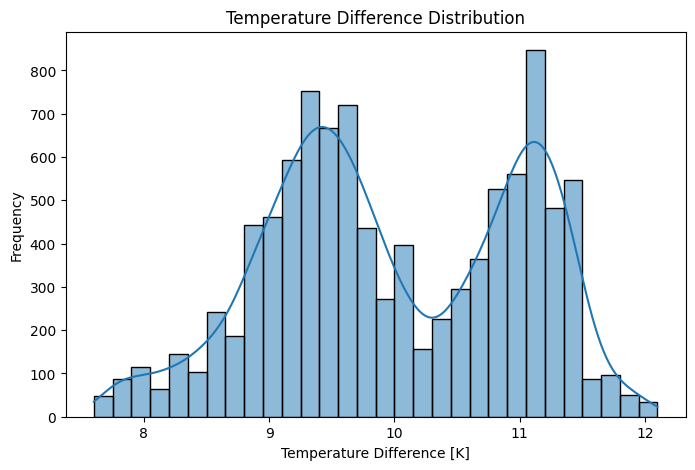

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df_clean["Temperature Difference [K]"],
    bins=30,
    kde=True
)

plt.title("Temperature Difference Distribution")
plt.xlabel("Temperature Difference [K]")
plt.ylabel("Frequency")

plt.show()

### Data Leakage Prevention

Data leakage occurs when information that should not be available during prediction is used during model training.

To prevent leakage, the following columns are excluded:

**Identifier Columns**
- UDI
- Product ID

**Failure-Mode Indicators**
- TWF
- HDF
- PWF
- OSF
- RNF

These failure-mode indicators are excluded because they directly describe machine failure mechanisms and may reveal information about the target.

**Target Variable**
- Machine failure

The target variable is separated from the input features.

Preprocessing transformations are fitted only on training data. The same transformations are applied to validation and test data without fitting them again.

This ensures a fair evaluation of model performance.

In [25]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature Difference [K]"
]

In [26]:

# Separate input features and target

target = "Machine failure"

excluded_columns = [
    "UDI",
    "Product ID",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

X = df_clean.drop(
    columns=excluded_columns + [target]
)

y = df_clean[target]

print("Selected Features:")
print(X.columns.tolist())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)


Selected Features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temperature Difference [K]']

Feature Shape: (10000, 7)
Target Shape: (10000,)


### Reproducibility

Reproducibility ensures that the same analytical workflow can be repeated under consistent conditions.

The following practices are implemented:

1. A fixed random seed of 42 is used.
2. Stratified sampling maintains the target class distribution across training, validation and test datasets.
3. Data preprocessing is fitted only on training data.
4. The same fitted transformations are applied to validation and test datasets.
5. Model configurations and experimental settings are documented.
6. Evaluation and experiment results are saved for future comparison.

These practices improve consistency and support reliable model evaluation.

In [27]:
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Random seed:", SEED)

Random seed: 42


# Train, Validation and Test Split

The dataset is divided into three parts:

- Training data: 70%
- Validation data: 15%
- Testing data: 15%


# Data Preprocessing

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split

# extract features and target from df_clean (which contains 'Temperature Difference [K]'
target = "Machine failure"
excluded_columns = [
    "UDI",
    "Product ID",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

X = df_clean.drop(columns=excluded_columns + [target])
y = df_clean[target]

# split to ensure train, validation, and test sets include 'Temperature Difference [K]'
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature Difference [K]"
]

categorical_features = ["Type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and testing data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Convert into NumPy arrays for ANN
X_train_processed = np.asarray(
    X_train_processed,
    dtype=np.float32
)

X_val_processed = np.asarray(
    X_val_processed,
    dtype=np.float32
)

X_test_processed = np.asarray(
    X_test_processed,
    dtype=np.float32
)

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

Training: (7000, 9)
Validation: (1500, 9)
Testing: (1500, 9)


# Phase 2 — Machine Learning and ANN Development


## Handling Class Imbalance

The AI4I 2020 dataset contains significantly more normal machine observations than machine failure observations.

This creates a class imbalance problem. A model may achieve high accuracy by predicting most observations as normal while missing actual machine failures.

To address this issue, class weights are used during model training.

- Logistic Regression uses `class_weight="balanced"`.
- Random Forest uses `class_weight="balanced_subsample"`.
- ANN uses the calculated class weights during training.

Class weights give greater importance to the minority failure class without removing valid observations from the dataset.

We use the training data to calculate class weights and do not use the test data for model selection.



In [29]:
# Check class distribution in each dataset
print("Training Class Distribution:")
print(y_train.value_counts())

print("\nValidation Class Distribution:")
print(y_val.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

# Calculate class weights before printing them
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced",classes=classes,y=y_train)
class_weights = dict(zip(classes, weights))

print("\nCalculated Class Weights:")
print(class_weights)


Training Class Distribution:
Machine failure
0    6763
1     237
Name: count, dtype: int64

Validation Class Distribution:
Machine failure
0    1449
1      51
Name: count, dtype: int64

Testing Class Distribution:
Machine failure
0    1449
1      51
Name: count, dtype: int64

Calculated Class Weights:
{np.int64(0): np.float64(0.5175218098477007), np.int64(1): np.float64(14.767932489451477)}



## Logistic Regression – Baseline Model
It estimates the probability of machine failure using the operational sensor measurements and product type.


In [30]:
log_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=SEED
)

log_model.fit(
    X_train_processed,
    y_train
)

log_val_prob = log_model.predict_proba(
    X_val_processed
)[:, 1]

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


## Random Forest Classifier – Ensemble Model
Each tree learns different patterns from the training data, and their predictions are combined to produce the final classification probability.


In [31]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=SEED,
    n_jobs=-1
)

rf_model.fit(
    X_train_processed,
    y_train
)

rf_val_prob = rf_model.predict_proba(
    X_val_processed
)[:, 1]

print("Random Forest Training Completed!")

Random Forest Training Completed!


## Artificial Neural Network
a feedforward neural network is developed to predict whether a machine is likely to fail.

In [32]:
def build_ann(input_dim, learning_rate=0.001):

    model = Sequential([
        Input(shape=(input_dim,)),

        Dense(
            64,
            activation="relu"
        ),

        Dropout(0.3),

        Dense(
            32,
            activation="relu"
        ),

        Dropout(0.2),

        Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),

        loss="binary_crossentropy",

        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall")
        ]
    )

    return model

In [33]:
# train the ANN
ann_model = build_ann(
    input_dim=X_train_processed.shape[1],
    learning_rate=0.001
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

ann_history = ann_model.fit(
    X_train_processed,
    y_train,
    validation_data=(
        X_val_processed,
        y_val
    ),
    epochs=60,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

print("ANN Training Completed!")

Epoch 1/60
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7064 - loss: 0.5645 - precision: 0.0784 - recall: 0.7131 - val_accuracy: 0.7953 - val_loss: 0.4740 - val_precision: 0.1213 - val_recall: 0.8039
Epoch 2/60
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7986 - loss: 0.4454 - precision: 0.1262 - recall: 0.8354 - val_accuracy: 0.8320 - val_loss: 0.3921 - val_precision: 0.1474 - val_recall: 0.8235
Epoch 3/60
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8177 - loss: 0.4085 - precision: 0.1400 - recall: 0.8523 - val_accuracy: 0.8380 - val_loss: 0.3675 - val_precision: 0.1496 - val_recall: 0.8039
Epoch 4/60
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8356 - loss: 0.3843 - precision: 0.1527 - recall: 0.8481 - val_accuracy: 0.8427 - val_loss: 0.3539 - val_precision: 0.1509 - val_recall: 0.7843
Epoch 5/60
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8446 - loss: 0.3409 - precision: 0.1610 - recall: 0.8523 - val_accuracy: 0.8627 - val_loss: 0.


### ANN Model Configuration

The ANN model contains two hidden layers with 64 and 32 neurons.

- Hidden layer activation: ReLU
- Output activation: Sigmoid
- Optimizer: Adam
- Learning rate: 0.001
- Loss function: Binary Crossentropy
- Maximum epochs: 60
- Batch size: 32
- Dropout rates: 0.3 and 0.2
- Callback: EarlyStopping
- Monitoring: Validation loss
- Patience: 8 epochs
- Restore best weights: True

The model uses class weights to handle the imbalanced target variable. Early stopping prevents unnecessary training when validation loss stops improving.



## Basic Hyperparameter Tuning



In [34]:

# Hyperparameter tuning using validation PR-AUC

tuning_results = []

# Logistic Regression candidates
for c_value in [0.1, 1.0, 10.0]:

    model = LogisticRegression(
        C=c_value,
        class_weight="balanced",
        max_iter=2000,
        random_state=SEED
    )

    model.fit(X_train_processed, y_train)

    probabilities = model.predict_proba(
        X_val_processed
    )[:, 1]

    pr_auc = average_precision_score(
        y_val,
        probabilities
    )

    tuning_results.append({
        "Model": "Logistic Regression",
        "Parameter": f"C={c_value}",
        "Validation PR-AUC": pr_auc
    })


# Random Forest candidates
for depth in [8, 12, 16]:

    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=depth,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=SEED,
        n_jobs=-1
    )

    model.fit(X_train_processed, y_train)

    probabilities = model.predict_proba(
        X_val_processed
    )[:, 1]

    pr_auc = average_precision_score(
        y_val,
        probabilities
    )

    tuning_results.append({
        "Model": "Random Forest",
        "Parameter": f"max_depth={depth}",
        "Validation PR-AUC": pr_auc
    })


# Display tuning results
tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df.sort_values(
        "Validation PR-AUC",
        ascending=False
    ).round(4)
)


,Model,Parameter,Validation PR-AUC
4,Random Forest,max_depth=12,0.7951
5,Random Forest,max_depth=16,0.7912
3,Random Forest,max_depth=8,0.7781
0,Logistic Regression,C=0.1,0.3855
2,Logistic Regression,C=10.0,0.3828
1,Logistic Regression,C=1.0,0.3828


In [35]:

# Select best Logistic Regression configuration
best_log_row = (
    tuning_df[
        tuning_df["Model"] == "Logistic Regression"
    ]
    .sort_values(
        "Validation PR-AUC",
        ascending=False
    )
    .iloc[0]
)

best_c = float(
    best_log_row["Parameter"].split("=")[1]
)

log_model = LogisticRegression(
    C=best_c,
    class_weight="balanced",
    max_iter=2000,
    random_state=SEED
)

log_model.fit(X_train_processed, y_train)

log_val_prob = log_model.predict_proba(
    X_val_processed
)[:, 1]


# Select best Random Forest configuration
best_rf_row = (
    tuning_df[
        tuning_df["Model"] == "Random Forest"
    ]
    .sort_values(
        "Validation PR-AUC",
        ascending=False
    )
    .iloc[0]
)

best_depth = int(
    best_rf_row["Parameter"].split("=")[1]
)

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=best_depth,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=SEED,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_val_prob = rf_model.predict_proba(
    X_val_processed
)[:, 1]


print("Best Logistic Regression :", best_c)
print("Best Random Forest max_depth:", best_depth)


Best Logistic Regression : 0.1
Best Random Forest max_depth: 12



### Hyperparameter Tuning Results

Hyperparameter tuning was performed using validation PR-AUC.

The selected configurations were:

- Logistic Regression: C = 0.1
- Random Forest: Maximum depth = 12

These configurations achieved the highest validation PR-AUC among the tested candidates for their respective models.

The selected hyperparameters were used to retrain the models on the training dataset.

The test dataset was not used during hyperparameter selection.

The ANN configuration was kept unchanged for comparison.


# Phase 3 — Model Evaluation and Reliability Audit

##  Model Performance Comparison

We trained three classification models:

1. Logistic Regression
2. Random Forest
3. Artificial Neural Network

The models will be compared using the same validation and
test datasets.

Evaluation metrics:

- Precision: How many predicted failures were actually failures?
- Recall: How many actual failures were detected?
- F1-score: Balance between precision and recall.
- ROC-AUC: Ability to distinguish between the two classes.
- PR-AUC: Performance in identifying the minority failure class.

Accuracy alone is not sufficient because the dataset
contains highly imbalanced target classes.

In [36]:
def evaluate_model(y_true, probabilities, threshold=0.5):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),
        "PR-AUC": average_precision_score(
            y_true, probabilities
        )
    }

In [37]:
ann_val_prob = ann_model.predict(
    X_val_processed
).ravel()

validation_results = []

models_validation = {
    "Logistic Regression": log_val_prob,
    "Random Forest": rf_val_prob,
    "ANN": ann_val_prob
}

for name, probabilities in models_validation.items():

    scores = evaluate_model(
        y_val,
        probabilities,
        threshold=0.5
    )

    scores["Model"] = name

    validation_results.append(scores)

validation_df = pd.DataFrame(validation_results)

validation_df = validation_df.set_index("Model")

display(validation_df.round(4))

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,0.8353,0.1370,0.7255,0.2305,0.8761,0.3855
Random Forest,0.9833,0.7826,0.7059,0.7423,0.9729,0.7951
ANN,0.9267,0.2966,0.8431,0.4388,0.9670,0.6940


## Threshold Tuning and Business Costs

In [38]:
FN_COST = 1000
FP_COST = 100

def calculate_business_cost(
    y_true,
    probabilities,
    threshold
):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    total_cost = (
        fn * FN_COST +
        fp * FP_COST
    )

    return total_cost, tn, fp, fn, tp

In [39]:
threshold_results = []

for model_name, probabilities in models_validation.items():

    for threshold in np.arange(0.05, 0.96, 0.01):

        cost, tn, fp, fn, tp = calculate_business_cost(
            y_val,
            probabilities,
            threshold
        )

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Business Cost": cost,
            "TP": tp,
            "TN": tn,
            "FP": fp,
            "FN": fn
        })

threshold_df = pd.DataFrame(threshold_results)

best_thresholds = (
    threshold_df
    .sort_values("Business Cost")
    .groupby("Model")
    .first()
    .reset_index()
)

display(best_thresholds)

,Model,Threshold,Business Cost,TP,TN,FP,FN
0,ANN,0.78,13700,41,1412,37,10
1,Logistic Regression,0.69,32100,30,1338,111,21
2,Random Forest,0.20,10200,46,1397,52,5


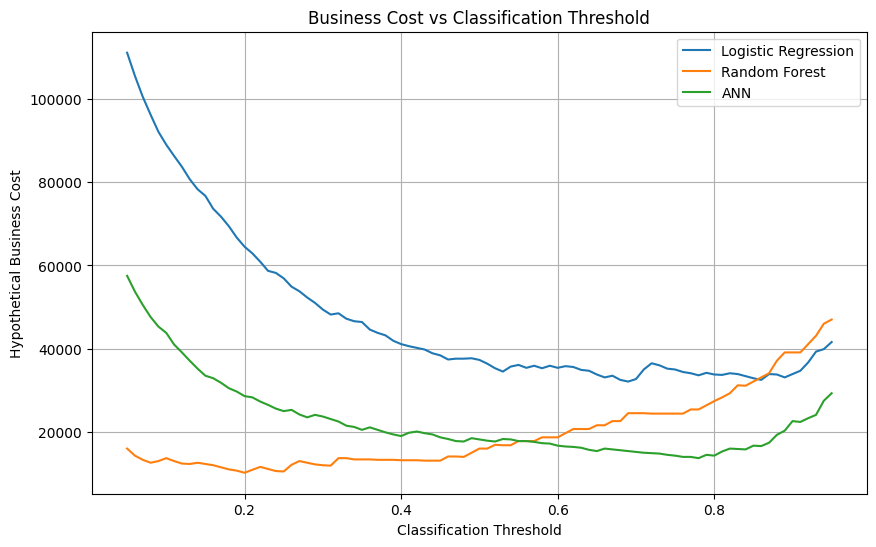

In [40]:

# Compare hypothetical validation cost across thresholds

plt.figure(figsize=(10, 6))

for model_name in threshold_df["Model"].unique():

    model_data = threshold_df[
        threshold_df["Model"] == model_name
    ]

    plt.plot(
        model_data["Threshold"],
        model_data["Business Cost"],
        label=model_name
    )

plt.xlabel("Classification Threshold")
plt.ylabel("Hypothetical Business Cost")
plt.title("Business Cost vs Classification Threshold")
plt.legend()
plt.grid(True)
plt.show()



### Hypothetical Business Cost Assumptions

To understand the business impact of incorrect predictions, I have considered the following hypothetical costs:

- False Positive (unnecessary inspection): 100 units.
- False Negative (missed machine failure): 1,000 units.

A missed machine failure is assumed to be more expensive because it can cause unexpected downtime and repair expenses.

Business Cost = (False Positives × 100) + (False Negatives × 1,000)

These values are hypothetical assumptions used for model comparison and do not represent actual company expenses.

The model thresholds are selected using validation data to minimize the estimated business cost.





### Threshold Sensitivity Analysis

The decision threshold determines the probability required to classify a machine as likely to fail.

- A lower threshold identifies more potential failures, increasing Recall but also increasing False Positives.
- A higher threshold reduces False Positives but may increase False Negatives.

I selected the thresholds by comparing hypothetical business costs using the validation dataset.

The selected thresholds are:

- Logistic Regression: 0.69
- Random Forest: 0.20
- ANN: 0.78

Random Forest achieved the lowest hypothetical validation business cost of 10,200 units.

Therefore, Random Forest is the preferred model based on the assumed inspection and missed-failure costs.


# Final Evaluation on Test Data


In [41]:
# Test probabilities
log_test_prob = log_model.predict_proba(
    X_test_processed
)[:, 1]

rf_test_prob = rf_model.predict_proba(
    X_test_processed
)[:, 1]

ann_test_prob = ann_model.predict(
    X_test_processed
).ravel()

test_probabilities = {
    "Logistic Regression": log_test_prob,
    "Random Forest": rf_test_prob,
    "ANN": ann_test_prob
}

# Use thresholds selected on validation data
test_results = []

for model_name, probabilities in test_probabilities.items():

    threshold = float(
        best_thresholds.loc[
            best_thresholds["Model"] == model_name,
            "Threshold"
        ].iloc[0]
    )

    scores = evaluate_model(
        y_test,
        probabilities,
        threshold
    )

    scores["Model"] = model_name
    scores["Threshold"] = threshold

    cost, tn, fp, fn, tp = calculate_business_cost(
        y_test,
        probabilities,
        threshold
    )

    scores["TN"] = tn
    scores["FP"] = fp
    scores["FN"] = fn
    scores["TP"] = tp
    scores["Business Cost"] = cost

    test_results.append(scores)

model_comparison = pd.DataFrame(test_results)

model_comparison = model_comparison.set_index("Model")

display(model_comparison.round(4))

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Threshold,TN,FP,FN,TP,Business Cost
Model,,,,,,,,,,,,
Logistic Regression,0.9193,0.2635,0.7647,0.3920,0.9031,0.3823,0.69,1340,109,12,39,22900
Random Forest,0.9533,0.4112,0.8627,0.5570,0.9725,0.8450,0.20,1386,63,7,44,13300
ANN,0.9653,0.4938,0.7843,0.6061,0.9705,0.7048,0.78,1408,41,11,40,15100



### Test Set Performance Interpretation

The models were evaluated on the held-out test dataset using thresholds selected from the validation dataset.

The results show:

1. Logistic Regression detected 39 out of 51 actual failures.
2. Random Forest detected 44 out of 51 actual failures.
3. ANN detected 40 out of 51 actual failures.

Random Forest achieved the highest recall of 86.27% and the highest PR-AUC of 0.8450.

ANN achieved the highest precision of 49.38% and F1-score of 0.6061.

Although ANN produced the highest accuracy, Random Forest achieved a better balance for identifying rare machine failures and minimizing the assumed business cost.


# Confusion Matrix

A confusion matrix helps us understand the types of
classification errors made by each model.

True Positive (TP):
Actual failure correctly predicted as failure.

True Negative (TN):
Normal operation correctly predicted as normal.

False Positive (FP):
Normal operation incorrectly predicted as failure.

False Negative (FN):
Actual failure incorrectly predicted as normal.

False Negatives are particularly important because
they represent machine failures that the model missed.

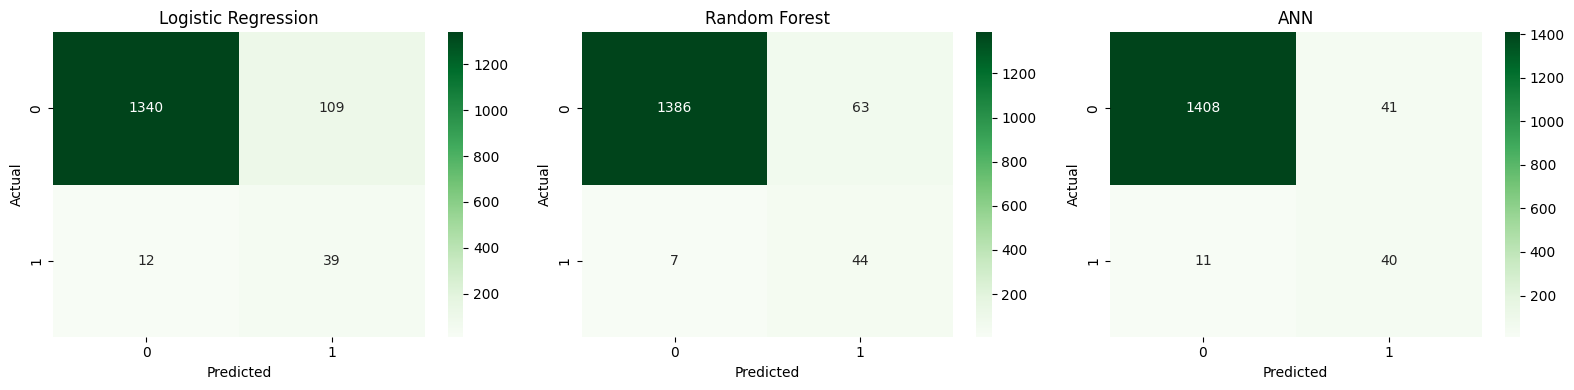

In [42]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4)
)

for ax, (model_name, probabilities) in zip(
    axes,
    test_probabilities.items()
):

    threshold = float(
        best_thresholds.loc[
            best_thresholds["Model"] == model_name,
            "Threshold"
        ].iloc[0]
    )

    predictions = (
        probabilities >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_test,
        predictions
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Greens",
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

## Classification Reports

In [43]:
for model_name, probabilities in test_probabilities.items():

    threshold = float(
        best_thresholds.loc[
            best_thresholds["Model"] == model_name,
            "Threshold"
        ].iloc[0]
    )

    predictions = (
        probabilities >= threshold
    ).astype(int)

    print("\n", "=" * 50)
    print(model_name)
    print("Threshold:", round(threshold, 3))

    print(
        classification_report(
            y_test,
            predictions,
            target_names=[
                "No Failure",
                "Failure"
            ],
            zero_division=0
        )
    )


Logistic Regression
Threshold: 0.69
              precision    recall  f1-score   support

  No Failure       0.99      0.92      0.96      1449
     Failure       0.26      0.76      0.39        51

    accuracy                           0.92      1500
   macro avg       0.63      0.84      0.67      1500
weighted avg       0.97      0.92      0.94      1500


Random Forest
Threshold: 0.2
              precision    recall  f1-score   support

  No Failure       0.99      0.96      0.98      1449
     Failure       0.41      0.86      0.56        51

    accuracy                           0.95      1500
   macro avg       0.70      0.91      0.77      1500
weighted avg       0.98      0.95      0.96      1500


ANN
Threshold: 0.78
              precision    recall  f1-score   support

  No Failure       0.99      0.97      0.98      1449
     Failure       0.49      0.78      0.61        51

    accuracy                           0.97      1500
   macro avg       0.74      0.88      0

## ROC Curve and Precision-Recall Curve

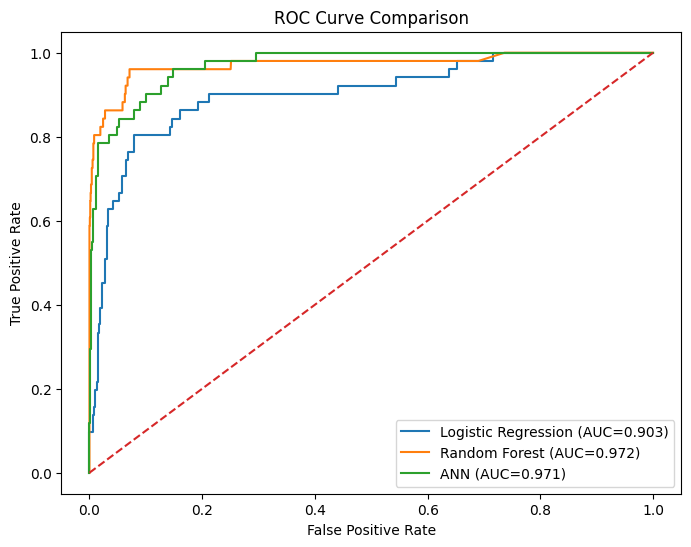

In [44]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for model_name, probabilities in test_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc_value = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC={auc_value:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

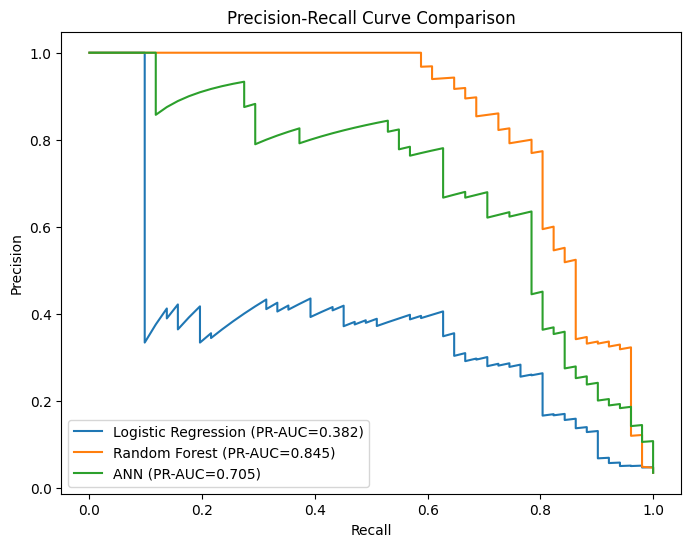

In [45]:
# precision and recall curve
plt.figure(figsize=(8, 6))

for model_name, probabilities in test_probabilities.items():

    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    pr_auc = average_precision_score(
        y_test,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (PR-AUC={pr_auc:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.show()


### ROC and Precision–Recall Curve Interpretation

The ROC curve evaluates the trade-off between the true positive rate and false positive rate across different thresholds.

The Precision–Recall curve is especially useful for this imbalanced dataset because machine failures are relatively rare.

Random Forest achieved the highest ROC-AUC (0.9725) and PR-AUC (0.8450) on the test dataset.

This indicates strong discrimination and better performance in identifying the minority failure class compared with the other evaluated models.


## Error Analysis

In [46]:
# Select the model with the lowest validation business cost
recommended_model_name = (
    best_thresholds.sort_values("Business Cost")
    .iloc[0]["Model"]
)

recommended_threshold = float(
    best_thresholds.loc[
        best_thresholds["Model"] == recommended_model_name,
        "Threshold"
    ].iloc[0]
)

recommended_probabilities = test_probabilities[
    recommended_model_name
]

recommended_predictions = (
    recommended_probabilities >= recommended_threshold
).astype(int)

error_analysis = X_test.copy()

error_analysis["Actual"] = np.array(y_test)

error_analysis["Predicted"] = recommended_predictions

error_analysis["Failure_Probability"] = (
    recommended_probabilities
)

error_analysis["Error_Type"] = "Correct Prediction"

error_analysis.loc[
    (error_analysis["Actual"] == 0) &
    (error_analysis["Predicted"] == 1),
    "Error_Type"
] = "False Positive"

error_analysis.loc[
    (error_analysis["Actual"] == 1) &
    (error_analysis["Predicted"] == 0),
    "Error_Type"
] = "False Negative"

display(
    error_analysis[
        error_analysis["Error_Type"] != "Correct Prediction"
    ].head(10)
)

print("\nError Type Counts:")
print(error_analysis["Error_Type"].value_counts())

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature Difference [K],Actual,Predicted,Failure_Probability,Error_Type
5819,L,301.3,311.0,1418,41.9,208,9.7,0,1,0.275843,False Positive
5996,M,300.5,310.2,1386,48.2,225,9.7,0,1,0.309103,False Positive
2904,L,300.6,309.4,2496,13.5,111,8.8,0,1,0.626077,False Positive
5390,H,302.8,312.3,1483,47.2,223,9.5,0,1,0.305284,False Positive
4028,L,302.0,310.9,1455,43.2,220,8.9,0,1,0.293002,False Positive
412,L,297.5,308.6,1388,48.2,203,11.1,0,1,0.208250,False Positive
4384,L,301.8,309.6,1443,42.7,231,7.8,0,1,0.333796,False Positive
5307,L,304.0,313.3,1530,34.8,211,9.3,0,1,0.350472,False Positive
5986,L,300.6,310.7,1440,52.5,200,10.1,0,1,0.263285,False Positive
2160,L,299.4,309.0,1507,41.0,213,9.6,0,1,0.203252,False Positive



Error Type Counts:
Error_Type
Correct Prediction    1430
False Positive          63
False Negative           7
Name: count, dtype: int64


In [47]:

# Display False Positive examples
print("False Positive Examples:")

display(
    error_analysis[
        error_analysis["Error_Type"] == "False Positive"
    ].head(5)
)

# Display False Negative examples
print("\nFalse Negative Examples:")

display(
    error_analysis[
        error_analysis["Error_Type"] == "False Negative"
    ].head(5)
)

# Compare error counts
print("\nError Summary:")

display(
    error_analysis["Error_Type"].value_counts()
)


False Positive Examples:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature Difference [K],Actual,Predicted,Failure_Probability,Error_Type
5819,L,301.3,311.0,1418,41.9,208,9.7,0,1,0.275843,False Positive
5996,M,300.5,310.2,1386,48.2,225,9.7,0,1,0.309103,False Positive
2904,L,300.6,309.4,2496,13.5,111,8.8,0,1,0.626077,False Positive
5390,H,302.8,312.3,1483,47.2,223,9.5,0,1,0.305284,False Positive
4028,L,302.0,310.9,1455,43.2,220,8.9,0,1,0.293002,False Positive



False Negative Examples:


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature Difference [K],Actual,Predicted,Failure_Probability,Error_Type
1996,M,298.4,308.0,1416,38.2,198,9.6,1,0,0.000112,False Negative
2941,M,300.7,309.6,1996,19.8,203,8.9,1,0,0.128654,False Negative
9174,L,297.8,308.9,1871,25.6,200,11.1,1,0,0.010000,False Negative
7426,M,300.0,311.4,1692,29.0,216,11.4,1,0,0.124850,False Negative
8690,L,297.1,308.5,1323,44.4,207,11.4,1,0,0.136124,False Negative



Error Summary:


,count
Error_Type,
Correct Prediction,1430
False Positive,63
False Negative,7



### Error Analysis Findings

The Random Forest model was selected for error analysis because it achieved the lowest validation business cost.

On the test dataset:

- 63 normal machine observations were incorrectly classified as failures (False Positives).
- 7 actual machine failures were incorrectly classified as normal (False Negatives).

False Positives may lead to unnecessary inspections and maintenance checks.

False Negatives are more critical because they represent actual failures that the model did not identify.

The results show that the model still makes errors and should be used as a decision-support tool rather than as a replacement for maintenance experts.


##Overfitting Analysis

In [48]:

# Compare training and validation performance
# at the same threshold of 0.5

training_probabilities = {
    "Logistic Regression": log_model.predict_proba(
        X_train_processed
    )[:, 1],

    "Random Forest": rf_model.predict_proba(
        X_train_processed
    )[:, 1],

    "ANN": ann_model.predict(
        X_train_processed
    ).ravel()
}

validation_probabilities = {
    "Logistic Regression": log_val_prob,
    "Random Forest": rf_val_prob,
    "ANN": ann_val_prob
}

overfit_results = []

for model_name in training_probabilities:

    train_scores = evaluate_model(
        y_train,
        training_probabilities[model_name],
        threshold=0.5
    )

    val_scores = evaluate_model(
        y_val,
        validation_probabilities[model_name],
        threshold=0.5
    )

    overfit_results.append({
        "Model": model_name,
        "Training PR-AUC": train_scores["PR-AUC"],
        "Validation PR-AUC": val_scores["PR-AUC"],
        "PR-AUC Gap": (
            train_scores["PR-AUC"] -
            val_scores["PR-AUC"]
        )
    })

overfit_df = pd.DataFrame(overfit_results)

display(overfit_df.round(4))


219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


,Model,Training PR-AUC,Validation PR-AUC,PR-AUC Gap
0,Logistic Regression,0.4465,0.3855,0.0610
1,Random Forest,0.9965,0.7951,0.2014
2,ANN,0.7904,0.6940,0.0964



### Overfitting Analysis

I compared the training and validation PR-AUC scores to check whether the models are overfitting.

The observations are:

- Logistic Regression has a small performance gap of 0.0610.
- Random Forest has a larger gap of 0.2014, which indicates possible overfitting.
- ANN has a gap of 0.0964, showing a smaller difference between training and validation performance.

Random Forest performs extremely well on training data, but its validation performance is lower.

However, it still achieves the highest PR-AUC on the test dataset.

Therefore, Random Forest shows some signs of overfitting, but it still provides strong performance on unseen data.


## Sensitivity to Decision Thresholds

In [49]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = np.arange(0.05, 0.96, 0.01)

FN_COST = 1000  # Hypothetical missed-failure cost
FP_COST = 100   # Hypothetical inspection cost

model_probabilities = {
    "Logistic Regression": log_val_prob,
    "Random Forest": rf_val_prob,
    "ANN": ann_val_prob
}

threshold_results = []

for model_name, probabilities in model_probabilities.items():

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val,
            predictions,
            labels=[0, 1]
        ).ravel()

        precision = precision_score(
            y_val, predictions, zero_division=0
        )

        recall = recall_score(
            y_val, predictions, zero_division=0
        )

        f1 = f1_score(
            y_val, predictions, zero_division=0
        )

        total_cost = (
            FN_COST * fn +
            FP_COST * fp
        )

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1,
            "False Positives": fp,
            "False Negatives": fn,
            "Business Cost": total_cost
        })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Model,Threshold,Precision,Recall,F1-Score,False Positives,False Negatives,Business Cost
0,Logistic Regression,0.05,0.0434,0.9804,0.0832,1101,1,111100
1,Logistic Regression,0.06,0.0457,0.9804,0.0873,1045,1,105500
2,Logistic Regression,0.07,0.0478,0.9804,0.0912,995,1,100500
3,Logistic Regression,0.08,0.0499,0.9804,0.0950,952,1,96200
4,Logistic Regression,0.09,0.0520,0.9804,0.0988,911,1,92100
...,...,...,...,...,...,...,...,...
268,ANN,0.91,0.6818,0.5882,0.6316,14,21,22400
269,ANN,0.92,0.6905,0.5686,0.6237,13,22,23300
270,ANN,0.93,0.7179,0.5490,0.6222,11,23,24100
271,ANN,0.94,0.8276,0.4706,0.6000,5,27,27500


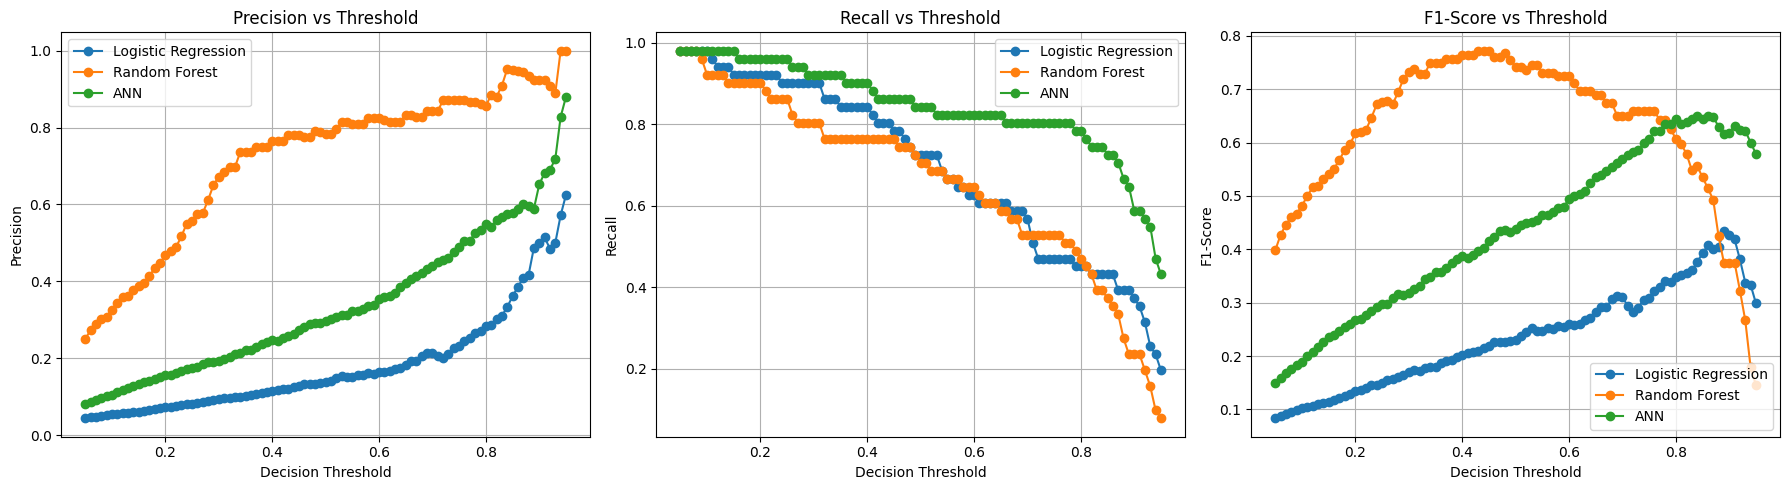

In [50]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ["Precision", "Recall", "F1-Score"]

for ax, metric in zip(axes, metrics):

    for model_name in model_probabilities:

        subset = threshold_df[
            threshold_df["Model"] == model_name
        ]

        ax.plot(
            subset["Threshold"],
            subset[metric],
            marker="o",
            label=model_name
        )

    ax.set_title(f"{metric} vs Threshold")
    ax.set_xlabel("Decision Threshold")
    ax.set_ylabel(metric)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()


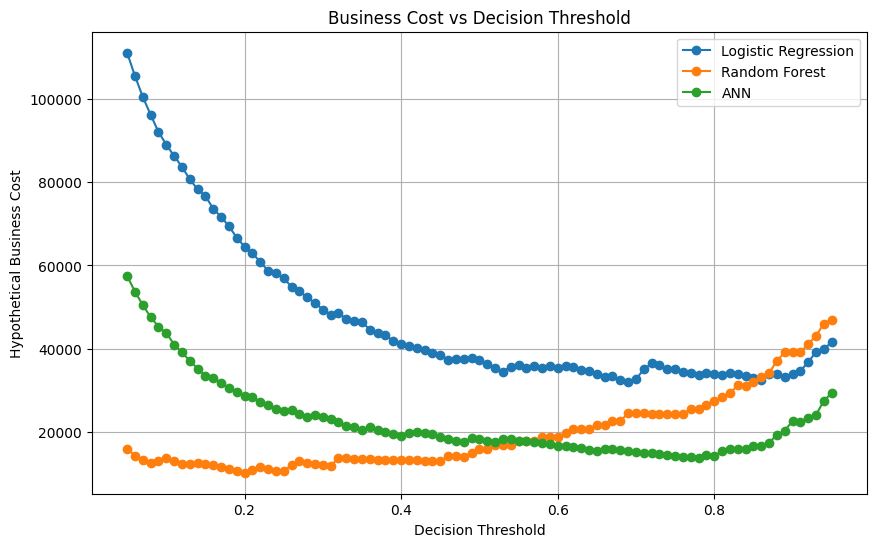

In [51]:

plt.figure(figsize=(10, 6))

for model_name in model_probabilities:

    subset = threshold_df[
        threshold_df["Model"] == model_name
    ]

    plt.plot(
        subset["Threshold"],
        subset["Business Cost"],
        marker="o",
        label=model_name
    )

plt.title("Business Cost vs Decision Threshold")
plt.xlabel("Decision Threshold")
plt.ylabel("Hypothetical Business Cost")
plt.legend()
plt.grid(True)
plt.show()


### Conclusion – Sensitivity to Decision Threshold

The threshold sensitivity analysis shows that changing the decision threshold significantly affects model performance and business cost.

A lower threshold increases the number of machines identified as potential failures, improving Recall but also increasing False Positives. A higher threshold reduces unnecessary alerts but may cause the model to miss actual failures.

Among the evaluated models, Random Forest with a threshold of 0.20 achieved the lowest hypothetical business cost of 10,200, with a Recall of 90.20%, Precision of 46.94%, and F1-score of 61.74%.

Therefore, Random Forest with a 0.20 decision threshold is recommended for further evaluation. The selected threshold should be validated using real maintenance costs and operational data before deployment.


# Final Model Recommendation

Based on the evaluation results, I recommend Random Forest with a decision threshold of 0.20.

It achieved the lowest hypothetical business cost on validation data (10,200 units) and also performed well on the test dataset, with a business cost of 13,300 units.

Random Forest achieved 86.27% Recall and 0.8450 PR-AUC on the test dataset, making it effective at identifying machine failures.

Although ANN achieved a higher test F1-score and Precision, Random Forest is preferred because identifying machine failures and reducing missed failures are the main priorities of this project.

The dataset is synthetic, and the business costs are hypothetical. Therefore, the model should be tested with real industrial data before deployment.

It should be used as a decision-support tool to help maintenance teams plan inspections rather than making automatic machine shutdown decisions.


# Phase 4 — Research and Controlled Experimentation


## Research Question and Hypothesis

### Research Question

Can optimizing the learning rate improve ANN performance, and can the best ANN configuration outperform the strongest traditional machine learning model, Random Forest?

### Hypothesis

**Null Hypothesis (H0):**

The best-performing ANN learning rate does not achieve a higher mean validation PR-AUC than Random Forest.

**Alternative Hypothesis (H1):**

The best-performing ANN learning rate achieves a higher mean validation PR-AUC than Random Forest.

### Primary Evaluation Metric

PR-AUC is selected as the primary evaluation metric because the dataset contains a highly imbalanced target variable.

The best ANN configuration will be compared against Random Forest using validation PR-AUC.


In [52]:

#  ANN Learning Rate Experiment

learning_rates = [0.0001, 0.001, 0.01]
random_seeds = [42, 21, 7]

experiment_results = []

for lr in learning_rates:

    for seed in random_seeds:

        print(f"\nLearning Rate: {lr}, Random Seed: {seed}")

        # Set random seed for reproducibility
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)

        # Build ANN with the selected learning rate
        model = build_ann(
            input_dim=X_train_processed.shape[1],
            learning_rate=lr
        )

        # Early stopping
        early_stop = EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True
        )

        # Train the model
        history = model.fit(
            X_train_processed,
            y_train,
            validation_data=(X_val_processed, y_val),
            epochs=60,
            batch_size=32,
            class_weight=class_weights,
            callbacks=[early_stop],
            verbose=0
        )

        # Predict validation probabilities
        val_prob = model.predict(
            X_val_processed,
            verbose=0
        ).ravel()

        # Use the same threshold for every experiment
        val_pred = (val_prob >= 0.5).astype(int)

        # Store results
        experiment_results.append({
            "Learning Rate": lr,
            "Random Seed": seed,

            "PR-AUC": average_precision_score(
                y_val, val_prob
            ),

            "Precision": precision_score(
                y_val, val_pred, zero_division=0
            ),

            "Recall": recall_score(
                y_val, val_pred, zero_division=0
            ),

            "F1-Score": f1_score(
                y_val, val_pred, zero_division=0
            ),

            "Best Epoch": np.argmin(
                history.history["val_loss"]
            ) + 1,

            "Epochs Run": len(history.history["loss"])
        })

print("\nAll ANN experiments completed!")

experiment_df = pd.DataFrame(experiment_results)

display(experiment_df.round(4))



Learning Rate: 0.0001, Random Seed: 42

Learning Rate: 0.0001, Random Seed: 21

Learning Rate: 0.0001, Random Seed: 7

Learning Rate: 0.001, Random Seed: 42

Learning Rate: 0.001, Random Seed: 21

Learning Rate: 0.001, Random Seed: 7

Learning Rate: 0.01, Random Seed: 42

Learning Rate: 0.01, Random Seed: 21

Learning Rate: 0.01, Random Seed: 7

All ANN experiments completed!


,Learning Rate,Random Seed,PR-AUC,Precision,Recall,F1-Score,Best Epoch,Epochs Run
0,0.0001,42,0.4938,0.1701,0.8039,0.2808,60,60
1,0.0001,21,0.4757,0.1864,0.8039,0.3026,60,60
2,0.0001,7,0.4911,0.1953,0.8235,0.3158,60,60
3,0.0010,42,0.6940,0.2966,0.8431,0.4388,26,34
4,0.0010,21,0.6808,0.3134,0.8235,0.4541,41,49
5,0.0010,7,0.6687,0.3407,0.9020,0.4946,22,30
6,0.0100,42,0.7011,0.3358,0.8824,0.4865,50,58
7,0.0100,21,0.7010,0.3077,0.8627,0.4536,27,35
8,0.0100,7,0.7055,0.3571,0.8824,0.5085,25,33



### Controlled Experiment Configuration

The ANN learning-rate experiment was designed by changing only the learning rate while keeping the remaining training conditions consistent.

| Parameter | Configuration |
|---|---|
| ANN Architecture | 64 → 32 → 1 |
| Hidden Activations | ReLU |
| Output Activation | Sigmoid |
| Optimizer | Adam |
| Loss Function | Binary Crossentropy |
| Learning Rates | 0.0001, 0.001, 0.01 |
| Random Seeds | 42, 21, 7 |
| Batch Size | 32 |
| Maximum Epochs | 60 |
| Early Stopping | Validation Loss |
| Patience | 8 |
| Restore Best Weights | True |
| Class Imbalance | Class Weights |
| Primary Evaluation Metric | PR-AUC |
| Training/Validation Split | Same fixed split |


Precision, Recall and F1-score were calculated using a fixed probability threshold of 0.50, while PR-AUC was used as the primary threshold-independent metric.


In [53]:
# Compare average performance and variability
# Calculate mean and standard deviation

experiment_summary = experiment_df.groupby(
    "Learning Rate"
).agg({
    "PR-AUC": ["mean", "std"],
    "Precision": ["mean", "std"],
    "Recall": ["mean", "std"],
    "F1-Score": ["mean", "std"]
}).round(4)

print("Learning Rate Experiment Summary")

display(experiment_summary)


Learning Rate Experiment Summary


PR-AUC         Precision          Recall         F1-Score  \
                 mean     std      mean     std    mean     std     mean   
Learning Rate                                                              
0.0001         0.4868  0.0097    0.1839  0.0128  0.8105  0.0113   0.2997   
0.0010         0.6812  0.0127    0.3169  0.0223  0.8562  0.0408   0.4625   
0.0100         0.7025  0.0026    0.3336  0.0248  0.8758  0.0113   0.4829   

                       
                  std  
Learning Rate          
0.0001         0.0177  
0.0010         0.0289  
0.0100         0.0276

In [54]:
# Compare ANN with traditional ML models

# Traditional ML validation performance

lr_pr_auc = average_precision_score(
    y_val, log_val_prob
)

rf_pr_auc = average_precision_score(
    y_val, rf_val_prob
)

# Average ANN PR-AUC for each learning rate
ann_comparison = experiment_df.groupby(
    "Learning Rate"
)["PR-AUC"].mean()

comparison_results = [
    {
        "Model": "Logistic Regression",
        "Validation PR-AUC": lr_pr_auc
    },
    {
        "Model": "Random Forest",
        "Validation PR-AUC": rf_pr_auc
    }
]

for lr, score in ann_comparison.items():

    comparison_results.append({
        "Model": f"ANN (LR={lr})",
        "Validation PR-AUC": score
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        "Validation PR-AUC",
        ascending=False
    ).round(4)
)


,Model,Validation PR-AUC
1,Random Forest,0.7951
4,ANN (LR=0.01),0.7025
3,ANN (LR=0.001),0.6812
2,ANN (LR=0.0001),0.4868
0,Logistic Regression,0.3855


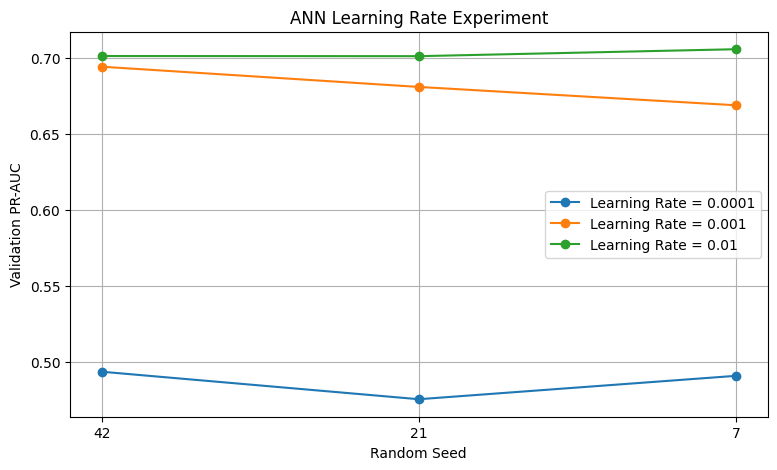

In [55]:

plt.figure(figsize=(9, 5))

for lr in learning_rates:

    subset = experiment_df[
        experiment_df["Learning Rate"] == lr
    ]

    plt.plot(
        subset["Random Seed"].astype(str),
        subset["PR-AUC"],
        marker="o",
        label=f"Learning Rate = {lr}"
    )

plt.title("ANN Learning Rate Experiment")
plt.xlabel("Random Seed")
plt.ylabel("Validation PR-AUC")
plt.legend()
plt.grid(True)
plt.show()



###  Experiment Observations

The controlled experiment evaluated three ANN learning rates (0.0001, 0.001, and 0.01) using three different random seeds (42, 21, and 7).

**Key Observations:**

1. The learning rate of 0.0001 achieved a mean PR-AUC of 0.4868.
2. Increasing the learning rate to 0.001 improved the mean PR-AUC to 0.6812.
3. The learning rate of 0.01 achieved the highest mean PR-AUC of 0.7025.
4. The learning rate of 0.01 also showed the lowest standard deviation (0.0026), indicating more consistent results across the three runs.
5. Random Forest achieved a higher validation PR-AUC (0.7951) than all tested ANN configurations.
6. ANN with learning rate 0.01 performed better than Logistic Regression (0.3855).

**Conclusion:**

The learning rate influenced ANN performance. Among the tested configurations, 0.01 provided the best and most consistent validation PR-AUC. However, Random Forest remained the strongest model based on validation PR-AUC.


In [56]:

# Create results directory
os.makedirs("results", exist_ok=True)

# Save model comparison results
model_comparison.reset_index().to_csv(
    "results/model_comparison.csv",
    index=False
)

# Save ANN experiment results
experiment_df.to_csv(
    "results/experiment_results.csv",
    index=False
)

print("Both CSV files saved successfully!")

print("1. results/model_comparison.csv")
print("2. results/experiment_results.csv")


Both CSV files saved successfully!
1. results/model_comparison.csv
2. results/experiment_results.csv



###  Final Hypothesis Decision

**Research Question:**

Does the ANN consistently outperform traditional machine learning models in predicting machine failures?

**Experimental Results:**

- Logistic Regression Validation PR-AUC: 0.3855
- Random Forest Validation PR-AUC: 0.7951
- ANN with Learning Rate 0.0001: 0.4868 (mean)
- ANN with Learning Rate 0.001: 0.6812 (mean)
- ANN with Learning Rate 0.01: 0.7025 (mean)


### Hypothesis Evaluation

The best ANN configuration, using a learning rate of 0.01, achieved a mean validation PR-AUC of 0.7025.

Random Forest achieved a validation PR-AUC of 0.7951.

Therefore, the tested ANN configuration did not outperform Random Forest.

The experimental results do not provide evidence in support of the alternative hypothesis.

However, ANN with learning rate 0.01 outperformed Logistic Regression, which achieved a validation PR-AUC of 0.3855.

The experiment demonstrates that learning-rate selection influences ANN performance.

The results are based on three random seeds per learning rate. They provide an indication of variability but are insufficient to establish statistical significance.

**Reliability and Variability:**

Three random seeds were used for each learning rate. The standard deviation of PR-AUC for learning rate 0.01 was 0.0026, indicating relatively consistent results across these three runs.

However, three runs are insufficient to establish statistical significance or guarantee generalization across different data splits.

**Final Conclusion:**

Random Forest achieved the best validation PR-AUC of 0.7951, while ANN with learning rate 0.01 was the best-performing ANN configuration with a mean PR-AUC of 0.7025.

Based on the available experimental evidence, Random Forest remains the stronger model for this predictive maintenance task.



# Phase 5 – Business Interpretation

##  Machine Failure Risk Classification

The objective of this phase is to translate machine failure predictions into practical maintenance decisions.

The selected Random Forest model estimates the probability of machine failure based on operating measurements such as temperature, rotational speed, torque, and tool wear.

Based on predicted failure probabilities, records are classified into three risk categories:

- Low Risk: Probability below 0.20
- Medium Risk: Probability from 0.20 to below 0.50
- High Risk: Probability of 0.50 or above

These are proposed operational risk bands, not validated probabilities of actual machine failure.

The 0.20 threshold is based on the validation threshold selected in Phase 3. The 0.50 boundary is an additional proposed boundary to prioritize more urgent inspections.


In [57]:


# Predict failure probabilities using Random Forest

rf_test_prob = rf_model.predict_proba(
    X_test_processed
)[:, 1]

# Create risk DataFrame with dataset row index
risk_df = pd.DataFrame({
    "Dataset_Row_Index": X_test.index,
    "Failure_Probability": rf_test_prob
})

# Assign risk categories
def assign_risk(probability):

    if probability >= 0.50:
        return "High Risk"

    elif probability >= 0.20:
        return "Medium Risk"

    else:
        return "Low Risk"

risk_df["Risk_Level"] = risk_df[
    "Failure_Probability"
].apply(assign_risk)

display(risk_df.head(10))


,Dataset_Row_Index,Failure_Probability,Risk_Level
0,1529,0.000000,Low Risk
1,8572,0.000000,Low Risk
2,4330,0.000112,Low Risk
3,1502,0.058524,Low Risk
4,9355,0.000000,Low Risk
5,7939,0.131665,Low Risk
6,2396,0.001964,Low Risk
7,3785,0.000000,Low Risk
8,8884,0.000000,Low Risk
9,5656,0.033134,Low Risk


,count
Risk_Level,
Low Risk,1393
Medium Risk,69
High Risk,38


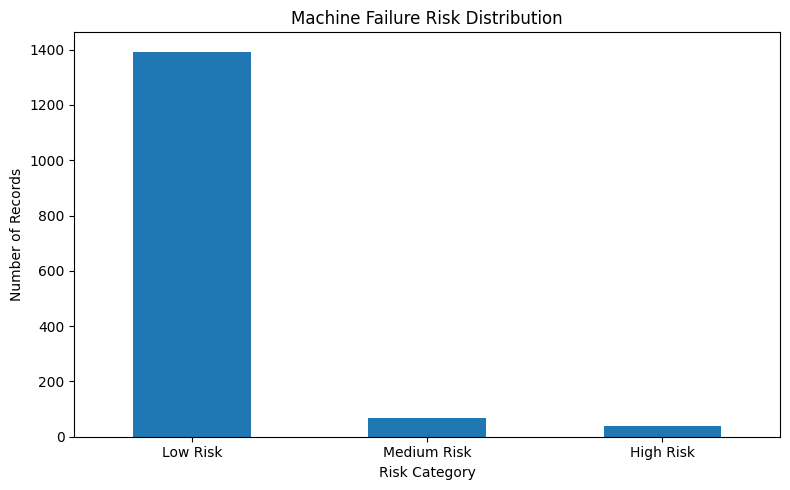

In [58]:

# Count records in each risk category

risk_distribution = (
    risk_df["Risk_Level"]
    .value_counts()
    .reindex(["Low Risk", "Medium Risk", "High Risk"])
    .fillna(0)
)

display(risk_distribution)

# Visualize risk distribution

risk_distribution.plot(
    kind="bar",
    figsize=(8, 5),
    title="Machine Failure Risk Distribution",
    xlabel="Risk Category",
    ylabel="Number of Records",
    rot=0
)

plt.tight_layout()
plt.show()


In [59]:

# Sort records by predicted failure probability

inspection_queue = risk_df.sort_values(
    by="Failure_Probability",
    ascending=False
).reset_index(drop=True)

# Assign inspection priority
inspection_queue.insert(
    0,
    "Inspection_Priority",
    range(1, len(inspection_queue) + 1)
)

display(inspection_queue.head(20))



,Inspection_Priority,Dataset_Row_Index,Failure_Probability,Risk_Level
0,1,4729,0.982592,High Risk
1,2,4081,0.975093,High Risk
2,3,4080,0.969971,High Risk
3,4,4270,0.963913,High Risk
4,5,4570,0.952745,High Risk
5,6,8398,0.919754,High Risk
6,7,6078,0.893718,High Risk
7,8,4565,0.892932,High Risk
8,9,6799,0.889561,High Risk
9,10,1391,0.888389,High Risk



##Important Sensor Patterns

The Random Forest feature importance values are used to identify which input variables contribute most to the model's predictions.

We also compare the median sensor measurements between records with normal operation and records with machine failures.

This analysis helps identify potential patterns in machine operating conditions.

Feature importance and observed differences indicate associations in this dataset. They do not prove that a particular sensor measurement causes machine failure.


,Feature,Importance
3,num__Torque [Nm],0.316051
2,num__Rotational speed [rpm],0.282242
4,num__Tool wear [min],0.208198
5,num__Temperature Difference [K],0.087855
0,num__Air temperature [K],0.054076
1,num__Process temperature [K],0.034970
7,cat__Type_L,0.007329
8,cat__Type_M,0.006162
6,cat__Type_H,0.003117


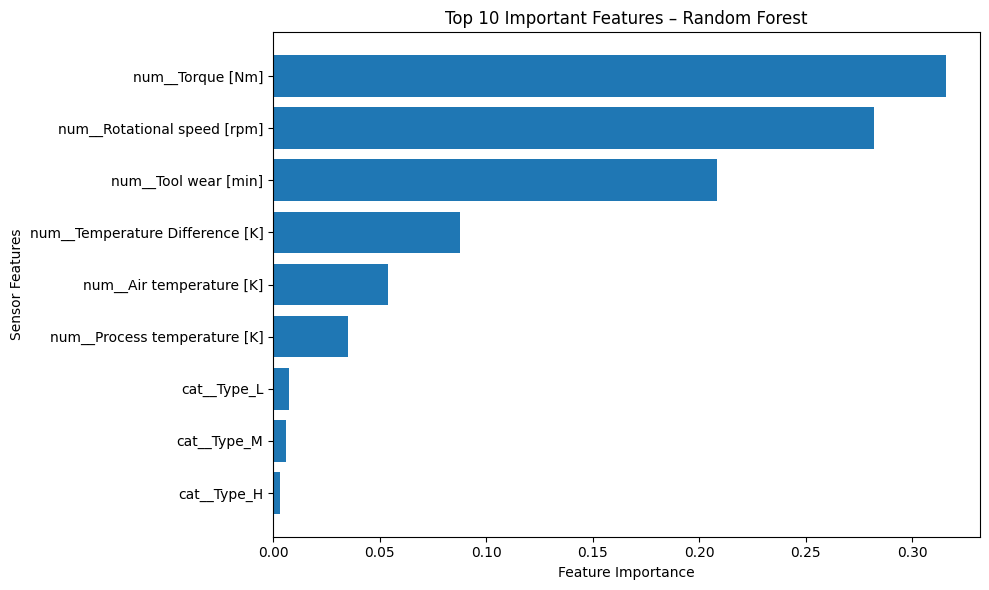

In [60]:

# Get feature names after preprocessing

feature_names = preprocessor.get_feature_names_out()

# Extract Random Forest feature importance

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Sort by importance

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

# Plot top 10 important features

top_features = importance_df.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Sensor Features")
plt.title("Top 10 Important Features – Random Forest")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


In [61]:

# Combine test features with actual target values

sensor_analysis = X_test.reset_index(drop=True).copy()

sensor_analysis["Machine failure"] = (
    y_test.reset_index(drop=True)
)

# Select numerical sensor columns

sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature Difference [K]"
]

# Compare median sensor values

sensor_comparison = sensor_analysis.groupby(
    "Machine failure"
)[sensor_columns].median().T

sensor_comparison.columns = [
    "Normal Operation",
    "Machine Failure"
]

display(sensor_comparison.round(2))


,Normal Operation,Machine Failure
Air temperature [K],299.9,300.7
Process temperature [K],310.1,310.3
Rotational speed [rpm],1500.0,1363.0
Torque [Nm],40.3,55.0
Tool wear [min],108.0,182.0
Temperature Difference [K],9.9,9.6



### Sensor Pattern Analysis – Findings

Based on the Random Forest feature importance results:

1. Torque was the most important feature, contributing approximately 31.61%.
2. Rotational speed contributed approximately 28.22%.
3. Tool wear contributed approximately 20.82%.
4. Temperature difference contributed approximately 8.79%.
5. Air temperature and process temperature had relatively lower feature importance.

The median sensor comparison showed:

- Failure records had higher median torque (55.0 Nm) compared with normal records (40.3 Nm).
- Failure records had higher median tool wear (182 minutes) compared with normal records (108 minutes).
- Failure records had lower median rotational speed (1363 rpm) compared with normal records (1500 rpm).

These patterns indicate associations between operating measurements and machine failure in the dataset.

Feature importance and median differences do not establish causation. Further engineering investigation is required to understand the underlying failure mechanisms.



##  Recommended Maintenance Actions

Based on the predicted risk categories, the following maintenance strategy is proposed.

### Low Risk

- Continue routine preventive maintenance.
- Monitor normal machine operating conditions.
- Perform scheduled inspections.

### Medium Risk

- Schedule a maintenance inspection.
- Review temperature, torque, rotational speed, and tool wear measurements.
- Check for unusual operating patterns.
- Increase monitoring frequency where appropriate.

### High Risk

- Prioritize the machine for immediate technical inspection.
- Ask maintenance engineers to verify sensor readings.
- Inspect relevant components for wear or abnormal operating conditions.
- Consider controlled shutdown if an engineer identifies an unsafe condition.

### Business Benefits

1. Helps prioritize maintenance activities.
2. May reduce unexpected machine downtime.
3. Supports better allocation of maintenance resources.
4. Helps identify potentially risky operating conditions earlier.
5. Supports data-driven maintenance planning.



## Real-World Deployment Constraints and Limitations

Although the predictive maintenance model provides useful results, some limitations must be considered before real-world deployment.

1. **Synthetic Dataset:** The AI4I 2020 dataset is synthetic and may not represent all real manufacturing environments.

2. **Limited Machine History:** The dataset is not a true per-machine time series. It cannot establish how an individual machine's condition changes over time.

3. **Class Imbalance:** Machine failure records are much fewer than normal records, which can affect prediction reliability.

4. **False Predictions:** False positives may result in unnecessary inspections, while false negatives may lead to missed failures.

5. **Sensor Reliability:** Real-world sensors may produce noisy, missing, delayed, or incorrect readings.

6. **Probability Calibration:** Predicted probabilities should be checked for calibration before interpreting them as actual failure probabilities.

7. **Model Monitoring:** The model should be monitored and retrained when machine conditions, equipment, or operating environments change.

8. **Human Supervision:** Maintenance decisions should involve qualified engineers. Model predictions should support, not replace, engineering judgment.

### Deployment Recommendation

Before deployment, the model should be tested using real industrial data collected from individual machines over time. It should undergo further validation, probability calibration, monitoring, and evaluation under actual maintenance conditions.



##  Business Interpretation Conclusion

The predictive maintenance solution converts Random Forest failure predictions into low, medium, and high-risk categories.

A prioritized inspection queue helps maintenance teams focus on records with higher predicted failure probabilities.

Feature importance and sensor comparisons provide insights into operating parameters associated with model predictions. However, these relationships do not establish causation.

The proposed maintenance strategy supports inspection prioritization, better resource allocation, and proactive maintenance planning.

Before real-world implementation, the model requires validation using actual machine data, reliable sensor inputs, probability calibration, continuous monitoring, and expert supervision.

Overall, the solution demonstrates how machine learning predictions can support maintenance planning and machine failure risk management.
